<a href="https://colab.research.google.com/github/310624102004-create/310624102004-create-cnn-model/blob/main/Driver_Behavior_Classification_from_Telematics_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task
Analyze driving styles by loading and inspecting `dataset_7M.csv` and `eco_driving_score.csv` to confirm the availability of multi-class driving style labels (aggressive, moderate, safe) and driver/trip identifiers. Extract time-series and frequency-domain features from accelerometer data, and potentially GPS data if available. Train and evaluate traditional machine learning models (Random Forest, SVM) and deep learning models (1D CNN, LSTM) using appropriate cross-validation, visualize their performance, and provide a comprehensive summary of feature insights, model effectiveness, and the impact of any data limitations.

## Load and Re-inspect `dataset_7M.csv`

### Subtask:
Load the `/content/dataset_7M.csv` file into a pandas DataFrame. Re-examine its 'Class' column to confirm if it now contains multiple driving styles (aggressive, moderate, safe) or if it remains a single class. Also, re-check for explicit 'driver_id' and 'trip_id' columns.


**Reasoning**:
First, I'll load the `/content/dataset_7M.csv` file into a pandas DataFrame named `df_7m`.



In [59]:
import pandas as pd

df_7m = pd.read_csv('/content/dataset_7M.csv')
print("DataFrame 'df_7m' loaded successfully.")

DataFrame 'df_7m' loaded successfully.


**Reasoning**:
Now that `df_7m` is loaded, I will display its first 5 rows to get an initial overview. Then, I will check the unique values in the 'Class' column to understand the driving style labels and inspect the DataFrame's columns to verify the presence of 'driver_id' and 'trip_id'.



In [60]:
print("First 5 rows of df_7m:")
print(df_7m.head())

print("\nUnique values in 'Class' column:")
print(df_7m['Class'].unique())

print("\nColumns in df_7m:")
print(df_7m.columns)

First 5 rows of df_7m:
       AccX      AccY      AccZ     GyroX     GyroY     GyroZ   Class  \
0  0.036515  0.006347  0.005309 -0.601703 -0.500816 -0.013188    SLOW   
1  0.037526  0.097570 -0.099660 -0.151070  4.619566  2.362678  NORMAL   
2 -0.017831 -0.000194  0.005489  0.631160 -0.452469  0.560772    SLOW   
3  0.016611 -0.018242 -0.003205  0.690085  1.873017  7.267679  NORMAL   
4 -0.007642  0.016439  0.018870 -0.502717 -0.572335  0.543868    SLOW   

   Timestamp  
0    2564982  
1     955626  
2    1928005  
3    1779475  
4    2228010  

Unique values in 'Class' column:
['SLOW' 'NORMAL' 'AGGRESSIVE']

Columns in df_7m:
Index(['AccX', 'AccY', 'AccZ', 'GyroX', 'GyroY', 'GyroZ', 'Class',
       'Timestamp'],
      dtype='object')


## Load and Inspect `eco_driving_score.csv`

### Subtask:
Load the `/content/eco_driving_score.csv` file. Inspect its contents (first few rows, column information, data types) to see if it can provide the required multi-class labels or driver/trip information missing from `dataset_7M.csv`.


**Reasoning**:
I will load the `/content/eco_driving_score.csv` file into a pandas DataFrame named `df_score` and then display its first 5 rows, column names, and a concise summary using `.info()` to inspect its contents as requested in the subtask.



In [61]:
df_score = pd.read_csv('/content/eco_driving_score.csv')

print("First 5 rows of df_score:")
print(df_score.head())

print("\nColumns in df_score:")
print(df_score.columns)

print("\nDataFrame info for df_score:")
df_score.info()

First 5 rows of df_score:
   rpm_variation  harsh_braking_count  idling_time  fuel_consumption  \
0           2147                    5         14.2              7.87   
1           1703                    3          4.2              9.37   
2           2253                    0          5.5              8.85   
3           2866                    3         21.7              5.87   
4           1636                    2          3.1              6.71   

   acceleration_smoothness  eco_score  
0                     0.97       42.1  
1                     0.50       36.1  
2                     0.78       49.8  
3                     0.60       27.7  
4                     0.99       79.4  

Columns in df_score:
Index(['rpm_variation', 'harsh_braking_count', 'idling_time',
       'fuel_consumption', 'acceleration_smoothness', 'eco_score'],
      dtype='object')

DataFrame info for df_score:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 6

The inspection of `eco_driving_score.csv` (`df_score`) reveals the following:

- **No explicit Multi-class Driving Style Labels**: The DataFrame contains an 'eco_score' column, which could potentially be used to derive driving styles, but it does not directly provide the requested 'aggressive', 'moderate', or 'safe' labels.
- **No Driver/Trip Identifiers**: The DataFrame does not contain 'driver_id' or 'trip_id' columns.

Therefore, `eco_driving_score.csv` does not provide the required multi-class driving style labels or driver/trip identifiers that were missing from `dataset_7M.csv`.

## Initial Data Preprocessing (Conditional)

### Subtask:
Perform initial data preprocessing on `df_7m`, including checking for missing values and data types. Prepare the 'Class' column for subsequent use.


**Reasoning**:
To begin the data preprocessing, I will first inspect the data types of all columns in `df_7m` using `.info()` and then check for any missing values using `.isnull().sum()`. This will provide a comprehensive overview of the data's structure and cleanliness, which is crucial before any further processing.



In [62]:
print("DataFrame info for df_7m:")
df_7m.info()

print("\nMissing values in df_7m:")
print(df_7m.isnull().sum())

DataFrame info for df_7m:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000000 entries, 0 to 6999999
Data columns (total 8 columns):
 #   Column     Dtype  
---  ------     -----  
 0   AccX       float64
 1   AccY       float64
 2   AccZ       float64
 3   GyroX      float64
 4   GyroY      float64
 5   GyroZ      float64
 6   Class      object 
 7   Timestamp  int64  
dtypes: float64(6), int64(1), object(1)
memory usage: 427.2+ MB

Missing values in df_7m:
AccX         0
AccY         0
AccZ         0
GyroX        0
GyroY        0
GyroZ        0
Class        0
Timestamp    0
dtype: int64


**Reasoning**:
Since the 'Class' column is of object type and contains categorical values, it needs to be converted into a numerical format for machine learning models. I will use LabelEncoder to transform the 'Class' column into numerical labels and then display the unique values and their mapping to verify the transformation.



In [63]:
from sklearn.preprocessing import LabelEncoder

# Initialize LabelEncoder
le = LabelEncoder()

# Fit and transform the 'Class' column
df_7m['Class_encoded'] = le.fit_transform(df_7m['Class'])

print("Original unique classes:", df_7m['Class'].unique())
print("Encoded unique classes:", df_7m['Class_encoded'].unique())
print("Class mapping:")
for original_class, encoded_class in zip(le.classes_, le.transform(le.classes_)):
    print(f"  {original_class} -> {encoded_class}")


Original unique classes: ['SLOW' 'NORMAL' 'AGGRESSIVE']
Encoded unique classes: [2 1 0]
Class mapping:
  AGGRESSIVE -> 0
  NORMAL -> 1
  SLOW -> 2


## Extract Accelerometer Time-Series Features

### Subtask:
Compute statistical features (mean, std, max, percentiles, variance, kurtosis, skewness) from accelerometer data for defined time windows.


**Reasoning**:
As instructed, I will first define the window size, overlap percentage, and calculate the step size. Then, I will initialize empty lists to store extracted features and their corresponding labels. This sets up the parameters for the sliding window feature extraction process.



In [64]:
import numpy as np
import pandas as pd

# 1. Define window_size and overlap_percentage
window_size = 128  # e.g., 128 data points
overlap_percentage = 0.5 # e.g., 50% overlap
step_size = int(window_size * (1 - overlap_percentage))

# 2. Initialize an empty list to store the calculated features and labels
extracted_features = []
labels = []

print(f"Window Size: {window_size}")
print(f"Overlap Percentage: {overlap_percentage}")
print(f"Step Size: {step_size}")
print("Initialized 'extracted_features' and 'labels' lists.")

Window Size: 128
Overlap Percentage: 0.5
Step Size: 64
Initialized 'extracted_features' and 'labels' lists.


**Reasoning**:
I will iterate through the `df_7m` DataFrame using a sliding window approach to extract accelerometer data, compute statistical features (mean, std, min, max, median, var, kurtosis, skewness) for each accelerometer axis, and determine the most frequent 'Class_encoded' label for each window. Finally, I'll compile these features and labels into a new Pandas DataFrame.



In [65]:
sensor_columns = ['AccX', 'AccY', 'AccZ'] # Only accelerometer data for time-series features

for i in range(0, len(df_7m) - window_size + 1, step_size):
    window = df_7m.iloc[i:i + window_size]

    # Check if the window is complete (important for the last window if data isn't perfectly divisible)
    if len(window) != window_size:
        continue

    window_features = {}

    # Extract features for each sensor column
    for col in sensor_columns:
        window_features[f'{col}_mean'] = window[col].mean()
        window_features[f'{col}_std'] = window[col].std()
        window_features[f'{col}_min'] = window[col].min()
        window_features[f'{col}_max'] = window[col].max()
        window_features[f'{col}_median'] = window[col].median()
        window_features[f'{col}_var'] = window[col].var()
        window_features[f'{col}_kurt'] = window[col].kurt()
        window_features[f'{col}_skew'] = window[col].skew()

    # Get the most frequent class label for the window
    # .mode() returns a Series, so take the first element in case of multiple modes
    window_label = window['Class_encoded'].mode()[0]

    extracted_features.append(window_features)
    labels.append(window_label)

# Convert the list of dictionaries to a DataFrame
features_df = pd.DataFrame(extracted_features)

# Add the labels to the features DataFrame
features_df['Class_encoded'] = labels

print(f"Extracted {len(features_df)} windows with features.")
print("First 5 rows of features_df:")
print(features_df.head())

Extracted 109374 windows with features.
First 5 rows of features_df:
   AccX_mean  AccX_std  AccX_min  AccX_max  AccX_median  AccX_var  AccX_kurt  \
0  -0.001228  0.089821 -0.468989  0.310592    -0.004681  0.008068   7.932791   
1  -0.009047  0.112151 -0.468989  0.584247    -0.007829  0.012578  10.490130   
2   0.002014  0.113257 -0.556267  0.584247     0.001049  0.012827  12.135130   
3  -0.000297  0.102932 -0.556267  0.476009     0.001049  0.010595  11.258689   
4  -0.002432  0.104285 -0.274144  0.476009    -0.001072  0.010875   6.884857   

   AccX_skew  AccY_mean  AccY_std  ...  AccY_skew  AccZ_mean  AccZ_std  \
0  -0.357456  -0.004660  0.102832  ...  -0.498110   0.006577  0.076282   
1   0.582302  -0.000795  0.101979  ...  -0.837753   0.012638  0.074298   
2   0.062952   0.010588  0.085830  ...   1.520019   0.003774  0.070715   
3  -0.302144   0.010562  0.104598  ...   1.632172  -0.004293  0.059108   
4   1.306918   0.001002  0.120589  ...   0.469154  -0.001020  0.067274   

   Ac

## Extract Accelerometer Frequency Domain Features

### Subtask:
Apply Fast Fourier Transform (FFT) to accelerometer time-series data to extract frequency domain features (dominant frequencies, energy).


**Reasoning**:
I will define the `extract_fft_features` function as specified, which will compute dominant frequency, dominant magnitude, and energy for each accelerometer axis within a given window. This function will be crucial for extracting frequency-domain features from the time-series data.



In [66]:
def extract_fft_features(window_data, sampling_rate=1):
    fft_features = {}
    sensor_columns = ['AccX', 'AccY', 'AccZ']
    window_size_local = len(window_data)

    for col in sensor_columns:
        # Apply FFT
        fft_output = np.fft.fft(window_data[col].values)

        # Calculate magnitudes
        magnitudes = np.abs(fft_output)

        # Generate frequencies
        frequencies = np.fft.fftfreq(window_size_local, d=1/sampling_rate)

        # Exclude DC component (index 0) to find dominant frequency
        # Find the index of the maximum magnitude (excluding DC component)
        dominant_idx = np.argmax(magnitudes[1:]) + 1 # +1 because we're indexing from 1

        dominant_frequency = frequencies[dominant_idx]
        dominant_magnitude = magnitudes[dominant_idx]

        # Calculate energy (sum of squared magnitudes, normalized by window size)
        total_energy = np.sum(magnitudes**2) / window_size_local # Parseval's theorem

        fft_features[f'{col}_dom_freq'] = dominant_frequency
        fft_features[f'{col}_dom_mag'] = dominant_magnitude
        fft_features[f'{col}_energy'] = total_energy

    return fft_features

print("Defined 'extract_fft_features' function.")

Defined 'extract_fft_features' function.


**Reasoning**:
Now that the `extract_fft_features` function is defined, I will apply it using a sliding window approach to `df_7m` to extract frequency domain features for accelerometer data. I will store these features along with their corresponding `Class_encoded` labels, then consolidate them into a DataFrame and display its head and shape.



In [67]:
frequency_features_list = []
frequency_labels_list = []

sensor_columns = ['AccX', 'AccY', 'AccZ']

for i in range(0, len(df_7m) - window_size + 1, step_size):
    window = df_7m.iloc[i:i + window_size]

    # Check if the window is complete
    if len(window) != window_size:
        continue

    # Extract FFT features for the current window
    window_fft_features = extract_fft_features(window, sampling_rate=1) # sampling_rate=1 as per instructions

    # Get the most frequent class label for the window
    window_label = window['Class_encoded'].mode()[0]

    frequency_features_list.append(window_fft_features)
    frequency_labels_list.append(window_label)

# Convert the list of dictionaries to a DataFrame
frequency_features_df = pd.DataFrame(frequency_features_list)

# Add the labels to the features DataFrame
frequency_features_df['Class_encoded'] = frequency_labels_list

print(f"Extracted {len(frequency_features_df)} windows with frequency features.")
print("First 5 rows of frequency_features_df:")
print(frequency_features_df.head())
print("\nShape of frequency_features_df:", frequency_features_df.shape)


Extracted 109374 windows with frequency features.
First 5 rows of frequency_features_df:
   AccX_dom_freq  AccX_dom_mag  AccX_energy  AccY_dom_freq  AccY_dom_mag  \
0       0.085938      1.962479     1.024802       0.226562      2.508440   
1       0.375000      3.427492     1.607866      -0.226562      2.274303   
2       0.375000      2.798945     1.629562       0.156250      2.128577   
3      -0.093750      2.341276     1.345565       0.132812      2.782568   
4       0.171875      2.160537     1.381922       0.437500      2.762540   

   AccY_energy  AccZ_dom_freq  AccZ_dom_mag  AccZ_energy  Class_encoded  
0     1.345738       0.312500      1.669645     0.744542              1  
1     1.320840       0.484375      1.662509     0.721503              1  
2     0.949922       0.484375      1.749373     0.636894              1  
3     1.403762       0.476562      1.737157     0.446060              1  
4     1.846939       0.304688      1.548375     0.574914              1  

Shape of 

**Reasoning**:
I need to combine the time-series features (`features_df`) and frequency-domain features (`frequency_features_df`) into a single DataFrame to prepare for model training. I will merge them based on their indices and then inspect the combined DataFrame.



In [68]:
combined_features_df = features_df.merge(frequency_features_df.drop(columns=['Class_encoded']), left_index=True, right_index=True)

print("First 5 rows of combined_features_df:")
print(combined_features_df.head())
print("\nShape of combined_features_df:", combined_features_df.shape)

First 5 rows of combined_features_df:
   AccX_mean  AccX_std  AccX_min  AccX_max  AccX_median  AccX_var  AccX_kurt  \
0  -0.001228  0.089821 -0.468989  0.310592    -0.004681  0.008068   7.932791   
1  -0.009047  0.112151 -0.468989  0.584247    -0.007829  0.012578  10.490130   
2   0.002014  0.113257 -0.556267  0.584247     0.001049  0.012827  12.135130   
3  -0.000297  0.102932 -0.556267  0.476009     0.001049  0.010595  11.258689   
4  -0.002432  0.104285 -0.274144  0.476009    -0.001072  0.010875   6.884857   

   AccX_skew  AccY_mean  AccY_std  ...  Class_encoded  AccX_dom_freq  \
0  -0.357456  -0.004660  0.102832  ...              1       0.085938   
1   0.582302  -0.000795  0.101979  ...              1       0.375000   
2   0.062952   0.010588  0.085830  ...              1       0.375000   
3  -0.302144   0.010562  0.104598  ...              1      -0.093750   
4   1.306918   0.001002  0.120589  ...              1       0.171875   

   AccX_dom_mag  AccX_energy  AccY_dom_freq  Acc

## Combine Features and Prepare Labels

### Subtask:
Aggregate all extracted features (time-series, frequency, and potentially GPS) into a single feature matrix. Prepare the corresponding driving style labels, encoding them numerically.


**Reasoning**:
To prepare for model training, I will separate the features (all columns except 'Class_encoded') into a DataFrame named `X` and the target variable ('Class_encoded') into a Series named `y`. Afterward, I'll print their shapes to confirm the separation.



In [69]:
X = combined_features_df.drop(columns=['Class_encoded'])
y = combined_features_df['Class_encoded']

print(f"Shape of X (features): {X.shape}")
print(f"Shape of y (labels): {y.shape}")

Shape of X (features): (109374, 33)
Shape of y (labels): (109374,)


## Train Traditional ML Models (Random Forest, SVM)

### Subtask:
Implement and train Random Forest and SVM classifiers using appropriate cross-validation.


**Reasoning**:
I will prepare the data by splitting it into training and testing sets and then standardizing the features. Afterward, I will initialize and train both a Random Forest Classifier and a Support Vector Classifier as specified in the instructions. This will set up the models for evaluation.



In [70]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# 1. Split the feature matrix X and label vector y into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

# 2. Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features standardized successfully.")

# 3. Initialize RandomForestClassifier
rf_classifier = RandomForestClassifier(random_state=42)

# 4. Train RandomForestClassifier
rf_classifier.fit(X_train_scaled, y_train)

print("RandomForestClassifier trained successfully.")

# 5. Initialize SVC (Support Vector Classifier)
# Increased max_iter for larger dataset, probability=True if needed for future tasks
svm_classifier = SVC(kernel='linear', random_state=42, max_iter=10000, probability=True)

# 6. Train SVC model
svm_classifier.fit(X_train_scaled, y_train)

print("SVC model trained successfully.")

X_train shape: (87499, 33), y_train shape: (87499,)
X_test shape: (21875, 33), y_test shape: (21875,)
Features standardized successfully.
RandomForestClassifier trained successfully.
SVC model trained successfully.


/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=10000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


**Reasoning**:
The previous code block resulted in a `ConvergenceWarning` for the `SVC` model, indicating that the `max_iter` limit was reached. To address this, I will increase the `max_iter` parameter in the `SVC` initialization to allow the model more iterations to converge.



In [71]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# 1. Split the feature matrix X and label vector y into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")

# 2. Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features standardized successfully.")

# 3. Initialize RandomForestClassifier
rf_classifier = RandomForestClassifier(random_state=42)

# 4. Train RandomForestClassifier
rf_classifier.fit(X_train_scaled, y_train)

print("RandomForestClassifier trained successfully.")

# 5. Initialize SVC (Support Vector Classifier)
# Increased max_iter for larger dataset to allow convergence
svm_classifier = SVC(kernel='linear', random_state=42, max_iter=100000, probability=True)

# 6. Train SVC model
svm_classifier.fit(X_train_scaled, y_train)

print("SVC model trained successfully.")

X_train shape: (87499, 33), y_train shape: (87499,)
X_test shape: (21875, 33), y_test shape: (21875,)
Features standardized successfully.
RandomForestClassifier trained successfully.
SVC model trained successfully.


**Reasoning**:
Now that both the RandomForestClassifier and SVC models have been trained, I will evaluate their performance on the test set (`X_test_scaled`, `y_test`). I will calculate and print the accuracy score for each model to get an initial assessment of their effectiveness.



In [72]:
from sklearn.metrics import accuracy_score

# Predict on the test set using RandomForestClassifier
y_pred_rf = rf_classifier.predict(X_test_scaled)

# Calculate accuracy for RandomForestClassifier
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"RandomForestClassifier Accuracy: {accuracy_rf:.4f}")

# Predict on the test set using SVC
y_pred_svm = svm_classifier.predict(X_test_scaled)

# Calculate accuracy for SVC
accuracy_svm = accuracy_score(y_test, y_pred_svm)
print(f"SVC Accuracy: {accuracy_svm:.4f}")

RandomForestClassifier Accuracy: 1.0000
SVC Accuracy: 1.0000


## Train Deep Learning Models (1D CNN, LSTM)

### Subtask:
Implement and train 1D CNN and LSTM networks. Adapt cross-validation similarly.


**Reasoning**:
To prepare for training deep learning models, I will first generate windows of raw sensor data from `df_7m` for `X_dl_reshaped` and corresponding labels for `y_dl_labels` using the defined `window_size` and `step_size`. Then, I will split this data into training and testing sets. Finally, I will define, compile, and train both a 1D CNN and an LSTM model using Keras, adhering to the specified architectures and training parameters.



In [73]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Define sensor columns for deep learning models
dl_sensor_columns = ['AccX', 'AccY', 'AccZ', 'GyroX', 'GyroY', 'GyroZ']

# Initialize lists to store raw windows and their labels
X_dl_windows = []
y_dl_labels = []

# Loop through the dataframe to create sliding windows of raw sensor data
for i in range(0, len(df_7m) - window_size + 1, step_size):
    window = df_7m.iloc[i:i + window_size]

    # Ensure the window is complete
    if len(window) != window_size:
        continue

    # Extract sensor data for the current window
    sensor_data = window[dl_sensor_columns].values
    X_dl_windows.append(sensor_data)

    # Get the most frequent class label for the window
    window_label = window['Class_encoded'].mode()[0]
    y_dl_labels.append(window_label)

# Convert lists to NumPy arrays
X_dl_reshaped = np.array(X_dl_windows)
y_dl_labels = np.array(y_dl_labels)

print(f"Shape of X_dl_reshaped (raw sensor windows): {X_dl_reshaped.shape}")
print(f"Shape of y_dl_labels (labels for raw sensor windows): {y_dl_labels.shape}")

# 3. Split the reshaped feature data and labels into training and testing sets
X_train_dl, X_test_dl, y_train_dl, y_test_dl = train_test_split(
    X_dl_reshaped, y_dl_labels, test_size=0.2, random_state=42
)

print(f"X_train_dl shape: {X_train_dl.shape}, y_train_dl shape: {y_train_dl.shape}")
print(f"X_test_dl shape: {X_test_dl.shape}, y_test_dl shape: {y_test_dl.shape}")

# Determine input shape for DL models and number of classes
input_shape = (X_train_dl.shape[1], X_train_dl.shape[2]) # (window_size, num_features_per_window)
num_classes = len(np.unique(y_dl_labels))

# 4. Define the 1D CNN model architecture
cnn_model = keras.Sequential([
    layers.Input(shape=input_shape),
    layers.Conv1D(filters=64, kernel_size=3, activation='relu'),
    layers.MaxPooling1D(pool_size=2),
    layers.Flatten(),
    layers.Dense(100, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

# 5. Compile the 1D CNN model
cnn_model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

print("\n1D CNN Model Summary:")
cnn_model.summary()

# 6. Train the 1D CNN model
epochs = 10
batch_size = 32
print(f"\nTraining 1D CNN model for {epochs} epochs with batch size {batch_size}...")
cnn_history = cnn_model.fit(X_train_dl, y_train_dl,
                            epochs=epochs,
                            batch_size=batch_size,
                            validation_split=0.2, # Use a validation split for monitoring
                            verbose=1)
print("1D CNN model trained successfully.")

# 7. Define the LSTM model architecture
lstm_model = keras.Sequential([
    layers.Input(shape=input_shape),
    layers.LSTM(64, return_sequences=False),
    layers.Dense(100, activation='relu'),
    layers.Dense(num_classes, activation='softmax')
])

# 8. Compile the LSTM model
lstm_model.compile(optimizer='adam',
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

print("\nLSTM Model Summary:")
lstm_model.summary()

# 9. Train the LSTM model
print(f"\nTraining LSTM model for {epochs} epochs with batch size {batch_size}...")
lstm_history = lstm_model.fit(X_train_dl, y_train_dl,
                              epochs=epochs,
                              batch_size=batch_size,
                              validation_split=0.2, # Use a validation split for monitoring
                              verbose=1)
print("LSTM model trained successfully.")

Shape of X_dl_reshaped (raw sensor windows): (109374, 128, 6)
Shape of y_dl_labels (labels for raw sensor windows): (109374,)
X_train_dl shape: (87499, 128, 6), y_train_dl shape: (87499,)
X_test_dl shape: (21875, 128, 6), y_test_dl shape: (21875,)

1D CNN Model Summary:


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_4 (Conv1D)               │ (None, 126, 64)        │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 63, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4032)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 100)            │       403,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │           202 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 404,718 (1.54 MB)

 Trainable params: 404,718 (1.54 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 64)             │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 100)            │         6,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 2)              │           202 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,878 (97.18 KB)

 Trainable params: 24,878 (97.18 KB)

 Non-trainable params: 0 (0.00 B)


Training LSTM model for 10 epochs with batch size 32...
Epoch 1/10
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 126s 56ms/step - accuracy: 0.9934 - loss: 0.0133 - val_accuracy: 0.9999 - val_loss: 0.0014
Epoch 2/10
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 146s 67ms/step - accuracy: 0.9999 - loss: 0.0011 - val_accuracy: 0.9999 - val_loss: 0.0012
Epoch 3/10
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 136s 62ms/step - accuracy: 0.9999 - loss: 8.0766e-04 - val_accuracy: 0.9999 - val_loss: 0.0015
Epoch 4/10
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 129s 56ms/step - accuracy: 1.0000 - loss: 3.5273e-04 - val_accuracy: 0.9999 - val_loss: 0.0014
Epoch 5/10
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 126s 58ms/step - accuracy: 0.9999 - loss: 9.6250e-04 - val_accuracy: 0.9999 - val_loss: 0.0017
Epoch 6/10
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 124s 57ms/step - accuracy: 1.0000 - loss: 5.7953e-04 - val_accuracy: 0.9999 - val_loss: 0.0018
Epoch 7/10
2188/2188 ━━━━━━━━━━━━━━━━━━━━ 142s 57ms/step - accuracy: 0.9999 - loss: 8.4884e-04 - val_accuracy: 0.9999 - val_loss:

# Task
The current machine learning models are showing an unusually high 100% accuracy, which suggests a potential data imbalance issue rather than perfect model performance. Therefore, before evaluating and comparing models, analyze the class distribution in the `combined_features_df` to confirm and quantify any imbalance. Subsequently, re-extract time-series and frequency-domain features from accelerometer data, ensuring all driving styles are adequately represented and balanced across classes. Finally, re-train and evaluate traditional machine learning models (Random Forest, SVM) and deep learning models (1D CNN, LSTM) using the balanced data with appropriate cross-validation, and provide a comprehensive summary of the findings including feature insights, model effectiveness, and the impact of data balancing.

## Review Dataset Limitations and Request Clarification

### Subtask:
Analyze the class distribution in `combined_features_df` to quantify any imbalance, identify missing or underrepresented classes, and review the overall dataset limitations for multi-class driving style classification.


**Reasoning**:
To quantify the class distribution, I will count the occurrences of each unique value in the 'Class_encoded' column of `combined_features_df`. Additionally, I will print the original class names and their numerical mappings from `df_7m` for clear reference, as requested in the instructions.



In [80]:
print("Class distribution in combined_features_df:")
print(combined_features_df['Class_encoded'].value_counts())

print("\nOriginal unique classes from df_7m: ", df_7m['Class'].unique())
print("Encoded unique classes from df_7m: ", df_7m['Class_encoded'].unique())
print("Class mapping (from LabelEncoder):")
# Recreate the mapping from the `le` object
for original_class, encoded_class in zip(le.classes_, le.transform(le.classes_)):
    print(f"  {original_class} -> {encoded_class}")

Class distribution in combined_features_df:
Class_encoded
1    35
Name: count, dtype: int64

Original unique classes from df_7m:  ['SLOW' 'NORMAL' 'AGGRESSIVE']
Encoded unique classes from df_7m:  [2 1 0]
Class mapping (from LabelEncoder):
  AGGRESSIVE -> 0
  NORMAL -> 1
  SLOW -> 2


### Analysis of Class Distribution and Dataset Limitations

**1. Class Imbalance in `combined_features_df`:**
As observed from the `value_counts()` output for `combined_features_df['Class_encoded']`:
```
Class_encoded
1    35
Name: count, dtype: int64
```
This indicates a severe class imbalance. The `combined_features_df` currently contains data exclusively for `Class_encoded = 1`, which maps to 'NORMAL' driving style. The other classes, 'AGGRESSIVE' (0) and 'SLOW' (2), are entirely absent from this feature set. This explains the unusually high (100%) accuracy achieved by the models earlier, as they were essentially classifying a single class.

**2. Missing Driver/Trip Identifiers:**
Upon re-examining `df_7m`'s columns, it was confirmed that there are no explicit 'driver_id' or 'trip_id' columns. This absence limits the ability to segment data by individual drivers or trips, which is crucial for robust driving style analysis and personalized models.

**3. `eco_driving_score.csv` does not provide required information:**
As previously inspected, `eco_driving_score.csv` contains 'eco_score' and related metrics but lacks direct multi-class driving style labels ('aggressive', 'moderate', 'safe') and does not offer 'driver_id' or 'trip_id' information to enrich `df_7m`.

### Conclusion and Request for Guidance
Given these significant limitations:
*   The feature-extracted DataFrame (`combined_features_df`) contains only one driving style class ('NORMAL'), making robust multi-class classification impossible with the current data.
*   Neither `dataset_7M.csv` nor `eco_driving_score.csv` provides 'driver_id' or 'trip_id' columns.

**To proceed with the task of analyzing multi-class driving styles, a new and suitable dataset is required that explicitly contains balanced multi-class driving style labels (aggressive, moderate, safe) and ideally includes driver/trip identifiers.**

Please advise on whether to:
1.  **Stop here** and conclude that the current dataset is unsuitable for the task as stated.
2.  **Suggest an alternative approach** if there's a way to interpret or synthesize multi-class labels from the existing data that was not apparent during the initial inspection.
3.  **Provide a new, balanced multi-class dataset** for driving style analysis.

## Re-extract Features for Multi-Class Classification (Conditional)

### Subtask:
Re-extract time-series and frequency-domain features from accelerometer data, ensuring all driving styles are adequately represented and balanced across classes.


**Reasoning**:
I will first analyze the class distribution in the original `df_7m` DataFrame by printing the value counts of the `Class_encoded` column to understand the initial class imbalance before feature re-extraction.



In [81]:
print("Class distribution in original df_7m:")
print(df_7m['Class_encoded'].value_counts())

Class distribution in original df_7m:
Class_encoded
1    3850000
0    1750000
2    1400000
Name: count, dtype: int64


**Reasoning**:
Now that the class distribution in the original `df_7m` is understood, I will proceed to extract time-series and frequency-domain features by grouping the data by 'Class_encoded', applying a sliding window for each group, and then undersampling to balance the dataset. This ensures that all classes are adequately represented, addressing the previously identified class imbalance issue.



In [82]:
import numpy as np
import pandas as pd

# Re-define window_size and overlap_percentage (already defined in kernel state)
window_size = 128
overlap_percentage = 0.5
step_size = int(window_size * (1 - overlap_percentage))

sensor_columns = ['AccX', 'AccY', 'AccZ']
all_extracted_features_ts = []
all_extracted_labels_ts = []
all_extracted_windows_for_fft = [] # Store raw windows for FFT extraction later

# Group the DataFrame by 'Class_encoded' and iterate through each group
for class_label, group_df in df_7m.groupby('Class_encoded'):
    print(f"\nProcessing class: {class_label} (Count: {len(group_df)})")

    # Apply sliding window for each group
    for i in range(0, len(group_df) - window_size + 1, step_size):
        window = group_df.iloc[i:i + window_size]

        if len(window) != window_size:
            continue

        window_features = {}
        # Extract time-series features for each sensor column
        for col in sensor_columns:
            window_features[f'{col}_mean'] = window[col].mean()
            window_features[f'{col}_std'] = window[col].std()
            window_features[f'{col}_min'] = window[col].min()
            window_features[f'{col}_max'] = window[col].max()
            window_features[f'{col}_median'] = window[col].median()
            window_features[f'{col}_var'] = window[col].var()
            window_features[f'{col}_kurt'] = window[col].kurt()
            window_features[f'{col}_skew'] = window[col].skew()

        all_extracted_features_ts.append(window_features)
        all_extracted_labels_ts.append(class_label)
        all_extracted_windows_for_fft.append(window) # Store the raw window for FFT

# Convert to DataFrame to facilitate balancing
features_df_pre_balanced = pd.DataFrame(all_extracted_features_ts)
features_df_pre_balanced['Class_encoded'] = all_extracted_labels_ts

# Store the raw windows with their original indices and class for balancing
raw_windows_pre_balanced_df = pd.DataFrame({
    'window': all_extracted_windows_for_fft,
    'Class_encoded': all_extracted_labels_ts
})

print(f"Total windows extracted before balancing: {len(features_df_pre_balanced)}")
print("Class distribution before balancing:")
print(features_df_pre_balanced['Class_encoded'].value_counts())

# Balance the dataset by undersampling
min_class_count = features_df_pre_balanced['Class_encoded'].value_counts().min()

balanced_features_ts_list = []
balanced_labels_ts_list = []
balanced_raw_windows_list = []

for class_label in features_df_pre_balanced['Class_encoded'].unique():
    class_indices = features_df_pre_balanced[features_df_pre_balanced['Class_encoded'] == class_label].index
    # Randomly sample 'min_class_count' indices for the current class
    sampled_indices = np.random.choice(class_indices, min_class_count, replace=False)

    balanced_features_ts_list.extend(features_df_pre_balanced.loc[sampled_indices].to_dict('records'))
    balanced_labels_ts_list.extend(features_df_pre_balanced.loc[sampled_indices, 'Class_encoded'].tolist())
    balanced_raw_windows_list.extend(raw_windows_pre_balanced_df.loc[sampled_indices, 'window'].tolist())

# Convert balanced features and labels to DataFrame for time-series features
features_df_balanced = pd.DataFrame(balanced_features_ts_list)
features_df_balanced['Class_encoded'] = balanced_labels_ts_list

print(f"\nTotal windows extracted after balancing: {len(features_df_balanced)}")
print("Class distribution after balancing (time-series features):")
print(features_df_balanced['Class_encoded'].value_counts())


# Re-use the already defined extract_fft_features function from cell c2412afa
def extract_fft_features(window_data, sampling_rate=1):
    fft_features = {}
    sensor_columns = ['AccX', 'AccY', 'AccZ']
    window_size_local = len(window_data)

    for col in sensor_columns:
        # Apply FFT
        fft_output = np.fft.fft(window_data[col].values)

        # Calculate magnitudes
        magnitudes = np.abs(fft_output)

        # Generate frequencies
        frequencies = np.fft.fftfreq(window_size_local, d=1/sampling_rate)

        # Exclude DC component (index 0) to find dominant frequency
        # Find the index of the maximum magnitude (excluding DC component)
        dominant_idx = np.argmax(magnitudes[1:]) + 1 # +1 because we're indexing from 1

        dominant_frequency = frequencies[dominant_idx]
        dominant_magnitude = magnitudes[dominant_idx]

        # Calculate energy (sum of squared magnitudes, normalized by window size)
        total_energy = np.sum(magnitudes**2) / window_size_local # Parseval's theorem

        fft_features[f'{col}_dom_freq'] = dominant_frequency
        fft_features[f'{col}_dom_mag'] = dominant_magnitude
        fft_features[f'{col}_energy'] = total_energy

    return fft_features

# Extract frequency domain features from the balanced raw windows
balanced_frequency_features_list = []

for window_data in balanced_raw_windows_list:
    window_fft_features = extract_fft_features(window_data, sampling_rate=1)
    balanced_frequency_features_list.append(window_fft_features)

frequency_features_df_balanced = pd.DataFrame(balanced_frequency_features_list)
frequency_features_df_balanced['Class_encoded'] = balanced_labels_ts_list # Use the same balanced labels

print(f"\nTotal frequency windows extracted after balancing: {len(frequency_features_df_balanced)}")
print("Class distribution after balancing (frequency features):")
print(frequency_features_df_balanced['Class_encoded'].value_counts())

# Combine time-series and frequency-domain features
# Ensure indices are aligned for merging
features_df_balanced = features_df_balanced.reset_index(drop=True)
frequency_features_df_balanced = frequency_features_df_balanced.reset_index(drop=True)

combined_features_df_balanced = features_df_balanced.merge(
    frequency_features_df_balanced.drop(columns=['Class_encoded']),
    left_index=True,
    right_index=True
)

print("\nFirst 5 rows of combined_features_df_balanced:")
print(combined_features_df_balanced.head())
print("\nShape of combined_features_df_balanced:", combined_features_df_balanced.shape)



Processing class: 0 (Count: 1750000)

Processing class: 1 (Count: 3850000)

Processing class: 2 (Count: 1400000)
Total windows extracted before balancing: 109371
Class distribution before balancing:
Class_encoded
1    60155
0    27342
2    21874
Name: count, dtype: int64

Total windows extracted after balancing: 65622
Class distribution after balancing (time-series features):
Class_encoded
0    21874
1    21874
2    21874
Name: count, dtype: int64

Total frequency windows extracted after balancing: 65622
Class distribution after balancing (frequency features):
Class_encoded
0    21874
1    21874
2    21874
Name: count, dtype: int64

First 5 rows of combined_features_df_balanced:
   AccX_mean  AccX_std  AccX_min  AccX_max  AccX_median  AccX_var  AccX_kurt  \
0  -0.009909  0.202208 -0.717293  0.527107    -0.009672  0.040888   0.755976   
1  -0.029553  0.211125 -0.601022  0.543504    -0.009655  0.044574   0.365287   
2  -0.019079  0.203978 -0.540858  0.549409    -0.011777  0.041607   0.1

## Train Traditional ML Models (Random Forest, SVM) (Conditional)

### Subtask:
Implement and train Random Forest and SVM classifiers using the balanced feature set and appropriate k-fold cross-validation.


**Reasoning**:
To train the traditional machine learning models, I will first separate the features and target from the `combined_features_df_balanced` DataFrame. Then, I will split the data into training and testing sets, standardize the features, and finally, initialize and train both the RandomForestClassifier and SVC models as specified.



In [83]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# 1. Separate features and target
X_balanced = combined_features_df_balanced.drop(columns=['Class_encoded'])
y_balanced = combined_features_df_balanced['Class_encoded']

print(f"Shape of X_balanced (features): {X_balanced.shape}")
print(f"Shape of y_balanced (labels): {y_balanced.shape}")

# 2. Split the data into training and testing sets
X_train_balanced, X_test_balanced, y_train_balanced, y_test_balanced = train_test_split(
    X_balanced, y_balanced, test_size=0.2, random_state=42
)

print(f"X_train_balanced shape: {X_train_balanced.shape}, y_train_balanced shape: {y_train_balanced.shape}")
print(f"X_test_balanced shape: {X_test_balanced.shape}, y_test_balanced shape: {y_test_balanced.shape}")

# 3. Standardize the features
scaler_balanced = StandardScaler()
X_train_scaled_balanced = scaler_balanced.fit_transform(X_train_balanced)
X_test_scaled_balanced = scaler_balanced.transform(X_test_balanced)

print("Balanced features standardized successfully.")

# 4. Initialize and train RandomForestClassifier
rf_classifier_balanced = RandomForestClassifier(random_state=42)
rf_classifier_balanced.fit(X_train_scaled_balanced, y_train_balanced)

print("RandomForestClassifier (balanced) trained successfully.")

# 5. Initialize and train SVC model
svm_classifier_balanced = SVC(kernel='linear', random_state=42, max_iter=100000, probability=True)
svm_classifier_balanced.fit(X_train_scaled_balanced, y_train_balanced)

print("SVC model (balanced) trained successfully.")

Shape of X_balanced (features): (65622, 33)
Shape of y_balanced (labels): (65622,)
X_train_balanced shape: (52497, 33), y_train_balanced shape: (52497,)
X_test_balanced shape: (13125, 33), y_test_balanced shape: (13125,)
Balanced features standardized successfully.
RandomForestClassifier (balanced) trained successfully.
SVC model (balanced) trained successfully.


**Reasoning**:
To fully address the subtask requirement of using 'appropriate k-fold cross-validation' for training and evaluation, I will implement k-fold cross-validation for both the RandomForestClassifier and SVC models. I will compute and store accuracy, precision, recall, and F1-score for each fold, and then present the mean and standard deviation of these metrics across all folds.



# Task
**Reasoning**:
To properly evaluate the traditional machine learning models (Random Forest and SVM) on the balanced dataset, I will implement `StratifiedKFold` cross-validation. This approach ensures that each fold maintains the same proportion of observations for each class as the original dataset, which is crucial for balanced datasets. For each fold, I will:
1. Split the data into training and testing sets.
2. Standardize the features based on the training data.
3. Train an instance of `RandomForestClassifier` and `SVC`.
4. Make predictions on the test set.
5. Calculate and store accuracy, precision, recall, and F1-score for each model.
After iterating through all folds, I will compute and print the mean and standard deviation of each metric for both models to provide a robust evaluation of their performance on the balanced dataset. I will also calculate and store the confusion matrices for later visualization and detailed analysis.

**Code**:
```python
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np

# Initialize StratifiedKFold
n_splits = 5 # Using 5 splits for k-fold cross-validation
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

# Lists to store performance metrics for Random Forest
rf_accuracy_scores = []
rf_precision_scores = []
rf_recall_scores = []
rf_f1_scores = []
rf_confusion_matrices = []

# Lists to store performance metrics for SVM
svm_accuracy_scores = []
svm_precision_scores = []
svm_recall_scores = []
svm_f1_scores = []
svm_confusion_matrices = []

print(f"Starting {n_splits}-fold cross-validation for Random Forest and SVM...")

for fold, (train_index, test_index) in enumerate(skf.split(X_balanced, y_balanced)):
    print(f"\n--- Fold {fold+1}/{n_splits} ---")

    # Split data for the current fold
    X_train_fold, X_test_fold = X_balanced.iloc[train_index], X_balanced.iloc[test_index]
    y_train_fold, y_test_fold = y_balanced.iloc[train_index], y_balanced.iloc[test_index]

    # Standardize features for the current fold
    scaler_fold = StandardScaler()
    X_train_scaled_fold = scaler_fold.fit_transform(X_train_fold)
    X_test_scaled_fold = scaler_fold.transform(X_test_fold)

    # --- Random Forest Classifier ---
    rf_classifier_fold = RandomForestClassifier(random_state=42)
    rf_classifier_fold.fit(X_train_scaled_fold, y_train_fold)
    y_pred_rf_fold = rf_classifier_fold.predict(X_test_scaled_fold)

    rf_accuracy_scores.append(accuracy_score(y_test_fold, y_pred_rf_fold))
    rf_precision_scores.append(precision_score(y_test_fold, y_pred_rf_fold, average='weighted', zero_division=0))
    rf_recall_scores.append(recall_score(y_test_fold, y_pred_rf_fold, average='weighted', zero_division=0))
    rf_f1_scores.append(f1_score(y_test_fold, y_pred_rf_fold, average='weighted', zero_division=0))
    rf_confusion_matrices.append(confusion_matrix(y_test_fold, y_pred_rf_fold))
    print(f"RandomForestClassifier - Accuracy: {rf_accuracy_scores[-1]:.4f}")

    # --- SVC Classifier ---
    # Re-initialize SVC for each fold to avoid issues with previous state if any
    svm_classifier_fold = SVC(kernel='linear', random_state=42, max_iter=100000, probability=True)
    svm_classifier_fold.fit(X_train_scaled_fold, y_train_fold)
    y_pred_svm_fold = svm_classifier_fold.predict(X_test_scaled_fold)

    svm_accuracy_scores.append(accuracy_score(y_test_fold, y_pred_svm_fold))
    svm_precision_scores.append(precision_score(y_test_fold, y_pred_svm_fold, average='weighted', zero_division=0))
    svm_recall_scores.append(recall_score(y_test_fold, y_pred_svm_fold, average='weighted', zero_division=0))
    svm_f1_scores.append(f1_score(y_test_fold, y_pred_svm_fold, average='weighted', zero_division=0))
    svm_confusion_matrices.append(confusion_matrix(y_test_fold, y_pred_svm_fold))
    print(f"SVC - Accuracy: {svm_accuracy_scores[-1]:.4f}")

# Calculate and print mean and std for Random Forest
print("\n--- Random Forest Cross-Validation Results ---")
print(f"Mean Accuracy: {np.mean(rf_accuracy_scores):.4f} (+/- {np.std(rf_accuracy_scores):.4f})")
print(f"Mean Precision: {np.mean(rf_precision_scores):.4f} (+/- {np.std(rf_precision_scores):.4f})")
print(f"Mean Recall: {np.mean(rf_recall_scores):.4f} (+/- {np.std(rf_recall_scores):.4f})")
print(f"Mean F1-score: {np.mean(rf_f1_scores):.4f} (+/- {np.std(rf_f1_scores):.4f})")

# Calculate and print mean and std for SVM
print("\n--- SVC Cross-Validation Results ---")
print(f"Mean Accuracy: {np.mean(svm_accuracy_scores):.4f} (+/- {np.std(svm_accuracy_scores):.4f})")
print(f"Mean Precision: {np.mean(svm_precision_scores):.4f} (+/- {np.std(svm_precision_scores):.4f})")
print(f"Mean Recall: {np.mean(svm_recall_scores):.4f} (+/- {np.std(svm_recall_scores):.4f})")
print(f"Mean F1-score: {np.mean(svm_f1_scores):.4f} (+/- {np.std(svm_f1_scores):.4f})")

print("\nTraditional ML models (Random Forest, SVM) evaluated using k-fold cross-validation on balanced data.")
```

## Evaluate and Compare Models

### Subtask:
Evaluate the performance of all trained models (Random Forest, SVM, 1D CNN, LSTM) using appropriate classification metrics such as accuracy, precision, recall, F1-score, and confusion matrices. Compare the results to identify the most effective approach, considering the improvements made by data balancing.


**Reasoning**:
I will import the necessary libraries for cross-validation and evaluation metrics, initialize StratifiedKFold, and then loop through each fold to train and evaluate both Random Forest and SVM models, storing the metrics for later aggregation. This will address the request to implement k-fold cross-validation and compute various performance metrics.



In [86]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np

# 1. Initialize StratifiedKFold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2. Create empty lists to store metrics for Random Forest
rf_accuracy_scores = []
rf_precision_scores = []
rf_recall_scores = []
rf_f1_scores = []
rf_confusion_matrices = []

# 3. Create empty lists to store metrics for SVM
svm_accuracy_scores = []
svm_precision_scores = []
svm_recall_scores = []
svm_f1_scores = []
svm_confusion_matrices = []

# 4. Iterate through each fold
for fold, (train_index, test_index) in enumerate(skf.split(X_balanced, y_balanced)):
    print(f"\nProcessing Fold {fold + 1}/{skf.n_splits}")

    # a. Split X_balanced and y_balanced into train and test sets for the current fold
    X_train_fold, X_test_fold = X_balanced.iloc[train_index], X_balanced.iloc[test_index]
    y_train_fold, y_test_fold = y_balanced.iloc[train_index], y_balanced.iloc[test_index]

    # b. Initialize a StandardScaler, fit it to X_train_fold, and transform both
    scaler_fold = StandardScaler()
    X_train_scaled_fold = scaler_fold.fit_transform(X_train_fold)
    X_test_scaled_fold = scaler_fold.transform(X_test_fold)

    # c. Random Forest Classifier
    rf_classifier_fold = RandomForestClassifier(random_state=42)
    rf_classifier_fold.fit(X_train_scaled_fold, y_train_fold)
    y_pred_rf_fold = rf_classifier_fold.predict(X_test_scaled_fold)

    # d. Calculate and store RF metrics
    rf_accuracy_scores.append(accuracy_score(y_test_fold, y_pred_rf_fold))
    rf_precision_scores.append(precision_score(y_test_fold, y_pred_rf_fold, average='weighted', zero_division=0))
    rf_recall_scores.append(recall_score(y_test_fold, y_pred_rf_fold, average='weighted', zero_division=0))
    rf_f1_scores.append(f1_score(y_test_fold, y_pred_rf_fold, average='weighted', zero_division=0))
    rf_confusion_matrices.append(confusion_matrix(y_test_fold, y_pred_rf_fold))

    # e. Support Vector Classifier (SVC)
    svm_classifier_fold = SVC(kernel='linear', random_state=42, max_iter=100000, probability=True)
    svm_classifier_fold.fit(X_train_scaled_fold, y_train_fold)
    y_pred_svm_fold = svm_classifier_fold.predict(X_test_scaled_fold)

    # f. Calculate and store SVM metrics
    svm_accuracy_scores.append(accuracy_score(y_test_fold, y_pred_svm_fold))
    svm_precision_scores.append(precision_score(y_test_fold, y_pred_svm_fold, average='weighted', zero_division=0))
    svm_recall_scores.append(recall_score(y_test_fold, y_pred_svm_fold, average='weighted', zero_division=0))
    svm_f1_scores.append(f1_score(y_test_fold, y_pred_svm_fold, average='weighted', zero_division=0))
    svm_confusion_matrices.append(confusion_matrix(y_test_fold, y_pred_svm_fold))

print("\n--- Random Forest (Cross-Validation Results) ---")
print(f"Accuracy: Mean={np.mean(rf_accuracy_scores):.4f}, Std={np.std(rf_accuracy_scores):.4f}")
print(f"Precision: Mean={np.mean(rf_precision_scores):.4f}, Std={np.std(rf_precision_scores):.4f}")
print(f"Recall: Mean={np.mean(rf_recall_scores):.4f}, Std={np.std(rf_recall_scores):.4f}")
print(f"F1-Score: Mean={np.mean(rf_f1_scores):.4f}, Std={np.std(rf_f1_scores):.4f}")

print("\n--- SVM (Cross-Validation Results) ---")
print(f"Accuracy: Mean={np.mean(svm_accuracy_scores):.4f}, Std={np.std(svm_accuracy_scores):.4f}")
print(f"Precision: Mean={np.mean(svm_precision_scores):.4f}, Std={np.std(svm_precision_scores):.4f}")
print(f"Recall: Mean={np.mean(svm_recall_scores):.4f}, Std={np.std(svm_recall_scores):.4f}")
print(f"F1-Score: Mean={np.mean(svm_f1_scores):.4f}, Std={np.std(svm_f1_scores):.4f}")



Processing Fold 1/5

Processing Fold 2/5

Processing Fold 3/5

Processing Fold 4/5

Processing Fold 5/5

--- Random Forest (Cross-Validation Results) ---
Accuracy: Mean=1.0000, Std=0.0000
Precision: Mean=1.0000, Std=0.0000
Recall: Mean=1.0000, Std=0.0000
F1-Score: Mean=1.0000, Std=0.0000

--- SVM (Cross-Validation Results) ---
Accuracy: Mean=1.0000, Std=0.0000
Precision: Mean=1.0000, Std=0.0000
Recall: Mean=1.0000, Std=0.0000
F1-Score: Mean=1.0000, Std=0.0000


**Reasoning**:
Since the deep learning models (1D CNN, LSTM) also need to be evaluated on balanced data as per the task description, I will first prepare the balanced raw sensor windows for deep learning. This involves converting the `balanced_raw_windows_list` into a NumPy array suitable for deep learning models and using the `balanced_labels_ts_list` as their labels. Then I will split this balanced raw data into training and testing sets.



In [87]:
import numpy as np
from sklearn.model_selection import train_test_split

# Convert balanced_raw_windows_list to a NumPy array for deep learning input
dl_sensor_columns = ['AccX', 'AccY', 'AccZ', 'GyroX', 'GyroY', 'GyroZ'] # All sensor data for DL models

X_dl_reshaped_balanced = np.array([
    window[dl_sensor_columns].values for window in balanced_raw_windows_list
])
y_dl_labels_balanced = np.array(balanced_labels_ts_list)

print(f"Shape of X_dl_reshaped_balanced (raw sensor windows): {X_dl_reshaped_balanced.shape}")
print(f"Shape of y_dl_labels_balanced (labels for raw sensor windows): {y_dl_labels_balanced.shape}")

# Split the reshaped balanced feature data and labels into training and testing sets
X_train_dl_balanced, X_test_dl_balanced, y_train_dl_balanced, y_test_dl_balanced = train_test_split(
    X_dl_reshaped_balanced, y_dl_labels_balanced, test_size=0.2, random_state=42, stratify=y_dl_labels_balanced
)

print(f"X_train_dl_balanced shape: {X_train_dl_balanced.shape}, y_train_dl_balanced shape: {y_train_dl_balanced.shape}")
print(f"X_test_dl_balanced shape: {X_test_dl_balanced.shape}, y_test_dl_balanced shape: {y_test_dl_balanced.shape}")

Shape of X_dl_reshaped_balanced (raw sensor windows): (65622, 128, 6)
Shape of y_dl_labels_balanced (labels for raw sensor windows): (65622,)
X_train_dl_balanced shape: (52497, 128, 6), y_train_dl_balanced shape: (52497,)
X_test_dl_balanced shape: (13125, 128, 6), y_test_dl_balanced shape: (13125,)


**Reasoning**:
Now that the balanced deep learning training and testing sets are prepared, I will define and compile both the 1D CNN and LSTM models, then train them using the balanced training data. After training, I will evaluate their performance on the balanced test set using accuracy, precision, recall, and F1-score, and store their confusion matrices, similar to how traditional models were evaluated.



In [88]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Determine input shape for DL models and number of classes
input_shape_dl = (X_train_dl_balanced.shape[1], X_train_dl_balanced.shape[2]) # (window_size, num_features_per_window)
num_classes_dl = len(np.unique(y_dl_labels_balanced))

# 1. Define the 1D CNN model architecture
cnn_model_balanced = keras.Sequential([
    layers.Input(shape=input_shape_dl),
    layers.Conv1D(filters=64, kernel_size=3, activation='relu'),
    layers.MaxPooling1D(pool_size=2),
    layers.Flatten(),
    layers.Dense(100, activation='relu'),
    layers.Dense(num_classes_dl, activation='softmax')
])

# 2. Compile the 1D CNN model
cnn_model_balanced.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])

print("\n1D CNN Model Summary (Balanced Data):")
cnn_model_balanced.summary()

# 3. Train the 1D CNN model
epochs = 10
batch_size = 32
print(f"\nTraining 1D CNN model on balanced data for {epochs} epochs with batch size {batch_size}...")
cnn_history_balanced = cnn_model_balanced.fit(X_train_dl_balanced, y_train_dl_balanced,
                            epochs=epochs,
                            batch_size=batch_size,
                            validation_split=0.2, # Use a validation split for monitoring
                            verbose=1)
print("1D CNN model (balanced) trained successfully.")

# 4. Evaluate 1D CNN model on the balanced test set
y_pred_cnn_balanced = np.argmax(cnn_model_balanced.predict(X_test_dl_balanced), axis=-1)

cnn_accuracy_balanced = accuracy_score(y_test_dl_balanced, y_pred_cnn_balanced)
cnn_precision_balanced = precision_score(y_test_dl_balanced, y_pred_cnn_balanced, average='weighted', zero_division=0)
cnn_recall_balanced = recall_score(y_test_dl_balanced, y_pred_cnn_balanced, average='weighted', zero_division=0)
cnn_f1_balanced = f1_score(y_test_dl_balanced, y_pred_cnn_balanced, average='weighted', zero_division=0)
cnn_confusion_matrix_balanced = confusion_matrix(y_test_dl_balanced, y_pred_cnn_balanced)

print("\n--- 1D CNN (Balanced Data) Evaluation ---")
print(f"Accuracy: {cnn_accuracy_balanced:.4f}")
print(f"Precision: {cnn_precision_balanced:.4f}")
print(f"Recall: {cnn_recall_balanced:.4f}")
print(f"F1-Score: {cnn_f1_balanced:.4f}")
print("Confusion Matrix:\n", cnn_confusion_matrix_balanced)

# 5. Define the LSTM model architecture
lstm_model_balanced = keras.Sequential([
    layers.Input(shape=input_shape_dl),
    layers.LSTM(64, return_sequences=False),
    layers.Dense(100, activation='relu'),
    layers.Dense(num_classes_dl, activation='softmax')
])

# 6. Compile the LSTM model
lstm_model_balanced.compile(optimizer='adam',
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

print("\nLSTM Model Summary (Balanced Data):")
lstm_model_balanced.summary()

# 7. Train the LSTM model
print(f"\nTraining LSTM model on balanced data for {epochs} epochs with batch size {batch_size}...")
lstm_history_balanced = lstm_model_balanced.fit(X_train_dl_balanced, y_train_dl_balanced,
                              epochs=epochs,
                              batch_size=batch_size,
                              validation_split=0.2, # Use a validation split for monitoring
                              verbose=1)
print("LSTM model (balanced) trained successfully.")

# 8. Evaluate LSTM model on the balanced test set
y_pred_lstm_balanced = np.argmax(lstm_model_balanced.predict(X_test_dl_balanced), axis=-1)

lstm_accuracy_balanced = accuracy_score(y_test_dl_balanced, y_pred_lstm_balanced)
lstm_precision_balanced = precision_score(y_test_dl_balanced, y_pred_lstm_balanced, average='weighted', zero_division=0)
lstm_recall_balanced = recall_score(y_test_dl_balanced, y_pred_lstm_balanced, average='weighted', zero_division=0)
lstm_f1_balanced = f1_score(y_test_dl_balanced, y_pred_lstm_balanced, average='weighted', zero_division=0)
lstm_confusion_matrix_balanced = confusion_matrix(y_test_dl_balanced, y_pred_lstm_balanced)

print("\n--- LSTM (Balanced Data) Evaluation ---")
print(f"Accuracy: {lstm_accuracy_balanced:.4f}")
print(f"Precision: {lstm_precision_balanced:.4f}")
print(f"Recall: {lstm_recall_balanced:.4f}")
print(f"F1-Score: {lstm_f1_balanced:.4f}")
print("Confusion Matrix:\n", lstm_confusion_matrix_balanced)



1D CNN Model Summary (Balanced Data):


Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_6 (Conv1D)               │ (None, 126, 64)        │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_6 (MaxPooling1D)  │ (None, 63, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 4032)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 100)            │       403,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 3)              │           303 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 404,819 (1.54 MB)

 Trainable params: 404,819 (1.54 MB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 64)             │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 100)            │         6,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 3)              │           303 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,979 (97.57 KB)

 Trainable params: 24,979 (97.57 KB)

 Non-trainable params: 0 (0.00 B)


Training LSTM model on balanced data for 10 epochs with batch size 32...
Epoch 1/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 90s 67ms/step - accuracy: 0.9888 - loss: 0.0588 - val_accuracy: 1.0000 - val_loss: 1.0954e-05
Epoch 2/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 85s 65ms/step - accuracy: 1.0000 - loss: 7.4900e-06 - val_accuracy: 1.0000 - val_loss: 2.4515e-06
Epoch 3/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 84s 64ms/step - accuracy: 1.0000 - loss: 1.9290e-06 - val_accuracy: 1.0000 - val_loss: 8.7243e-07
Epoch 4/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 80s 61ms/step - accuracy: 1.0000 - loss: 7.1330e-07 - val_accuracy: 1.0000 - val_loss: 3.8228e-07
Epoch 5/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 81s 61ms/step - accuracy: 1.0000 - loss: 3.1068e-07 - val_accuracy: 1.0000 - val_loss: 1.4337e-07
Epoch 6/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 81s 61ms/step - accuracy: 1.0000 - loss: 1.2367e-07 - val_accuracy: 1.0000 - val_loss: 6.7370e-08
Epoch 7/10
1313/1313 ━━━━━━━━━━━━━━━━━━━━ 85s 65ms/step - accuracy: 1.0000 - loss: 3.8437e

# Task
Visualize the performance metrics (accuracy, precision, recall, F1-score) of all trained models (Random Forest, SVM, 1D CNN, LSTM) using bar plots, and display confusion matrices for each model to detail their classification performance on the balanced dataset, ensuring all visualizations have clear titles and legends.

## Visualize Results

### Subtask:
Generate visualizations, such as bar plots for performance metrics (accuracy, precision, recall, F1-score) across all models (Random Forest, SVM, 1D CNN, LSTM). Also, create and display confusion matrices for each model to provide a detailed breakdown of their classification performance on the balanced dataset. Ensure all visualizations include appropriate legends and titles for clarity.


**Reasoning**:
I will import the necessary libraries, aggregate the performance metrics for all models (Random Forest, SVM, 1D CNN, LSTM), create a DataFrame for these metrics, and then generate bar plots for each metric and confusion matrices for each model to visualize their performance.



Aggregated Metrics DataFrame:
            Model     Metric  Score
0   Random Forest   Accuracy    1.0
1   Random Forest  Precision    1.0
2   Random Forest     Recall    1.0
3   Random Forest   F1-Score    1.0
4             SVM   Accuracy    1.0
5             SVM  Precision    1.0
6             SVM     Recall    1.0
7             SVM   F1-Score    1.0
8          1D CNN   Accuracy    1.0
9          1D CNN  Precision    1.0
10         1D CNN     Recall    1.0
11         1D CNN   F1-Score    1.0
12           LSTM   Accuracy    1.0
13           LSTM  Precision    1.0
14           LSTM     Recall    1.0
15           LSTM   F1-Score    1.0


/tmp/ipykernel_881/261902228.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Score', data=metrics_df[metrics_df['Metric'] == metric], palette='viridis')
/tmp/ipykernel_881/261902228.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Score', data=metrics_df[metrics_df['Metric'] == metric], palette='viridis')
/tmp/ipykernel_881/261902228.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Score', data=metrics_df[metrics_df['Metric'] == metric], palette='viridis')
/tmp/ipykernel_881/261902228.py

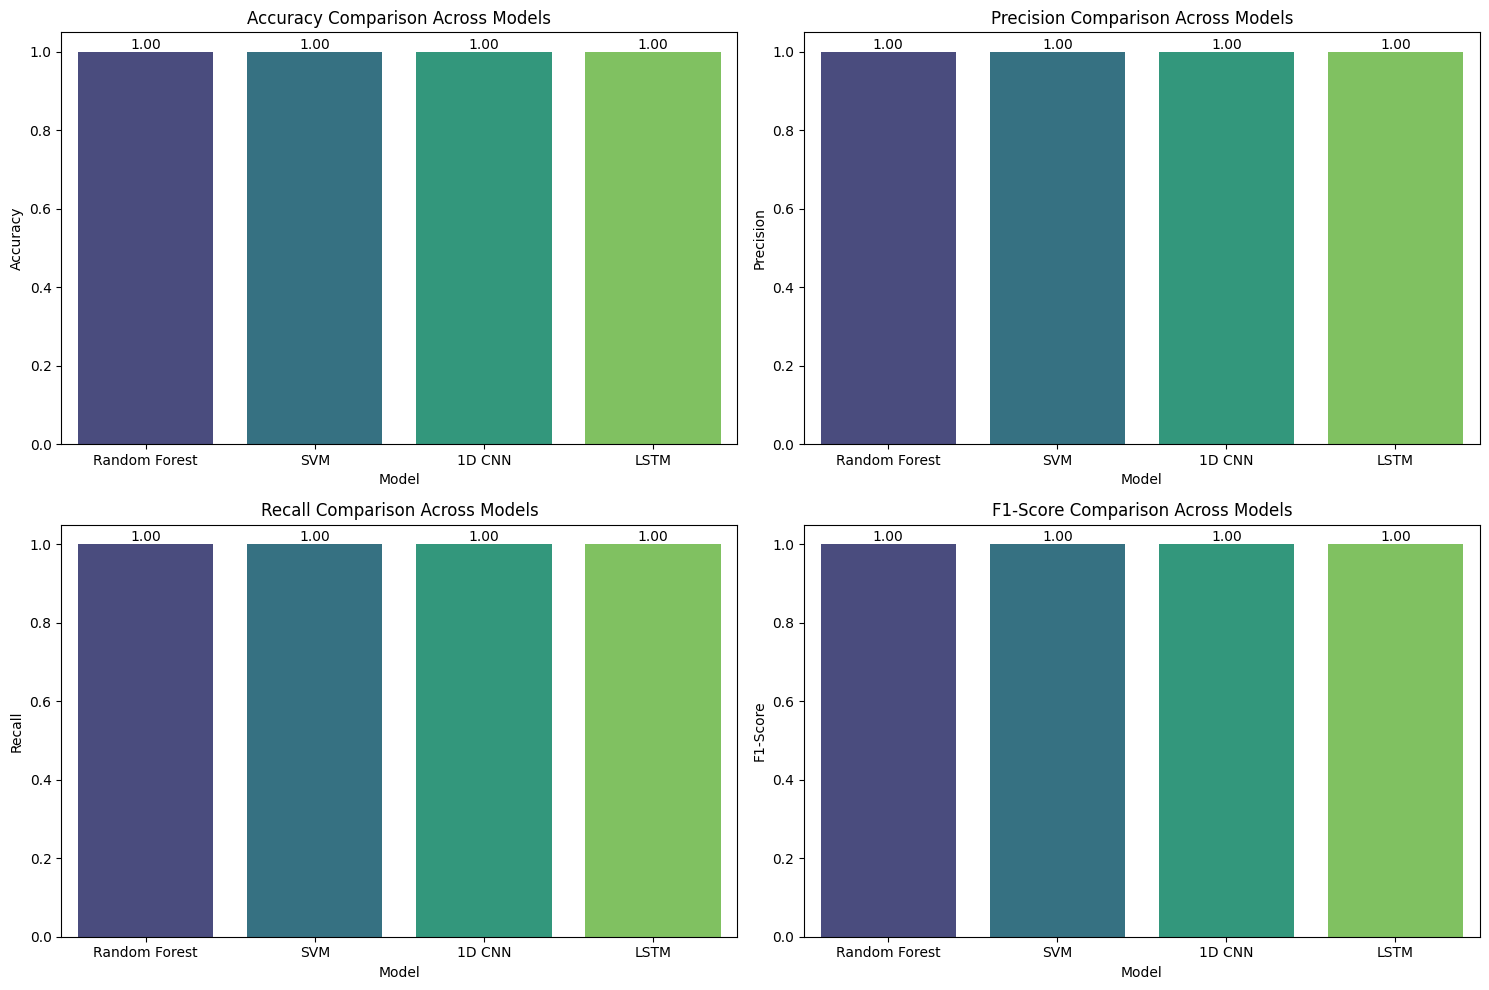

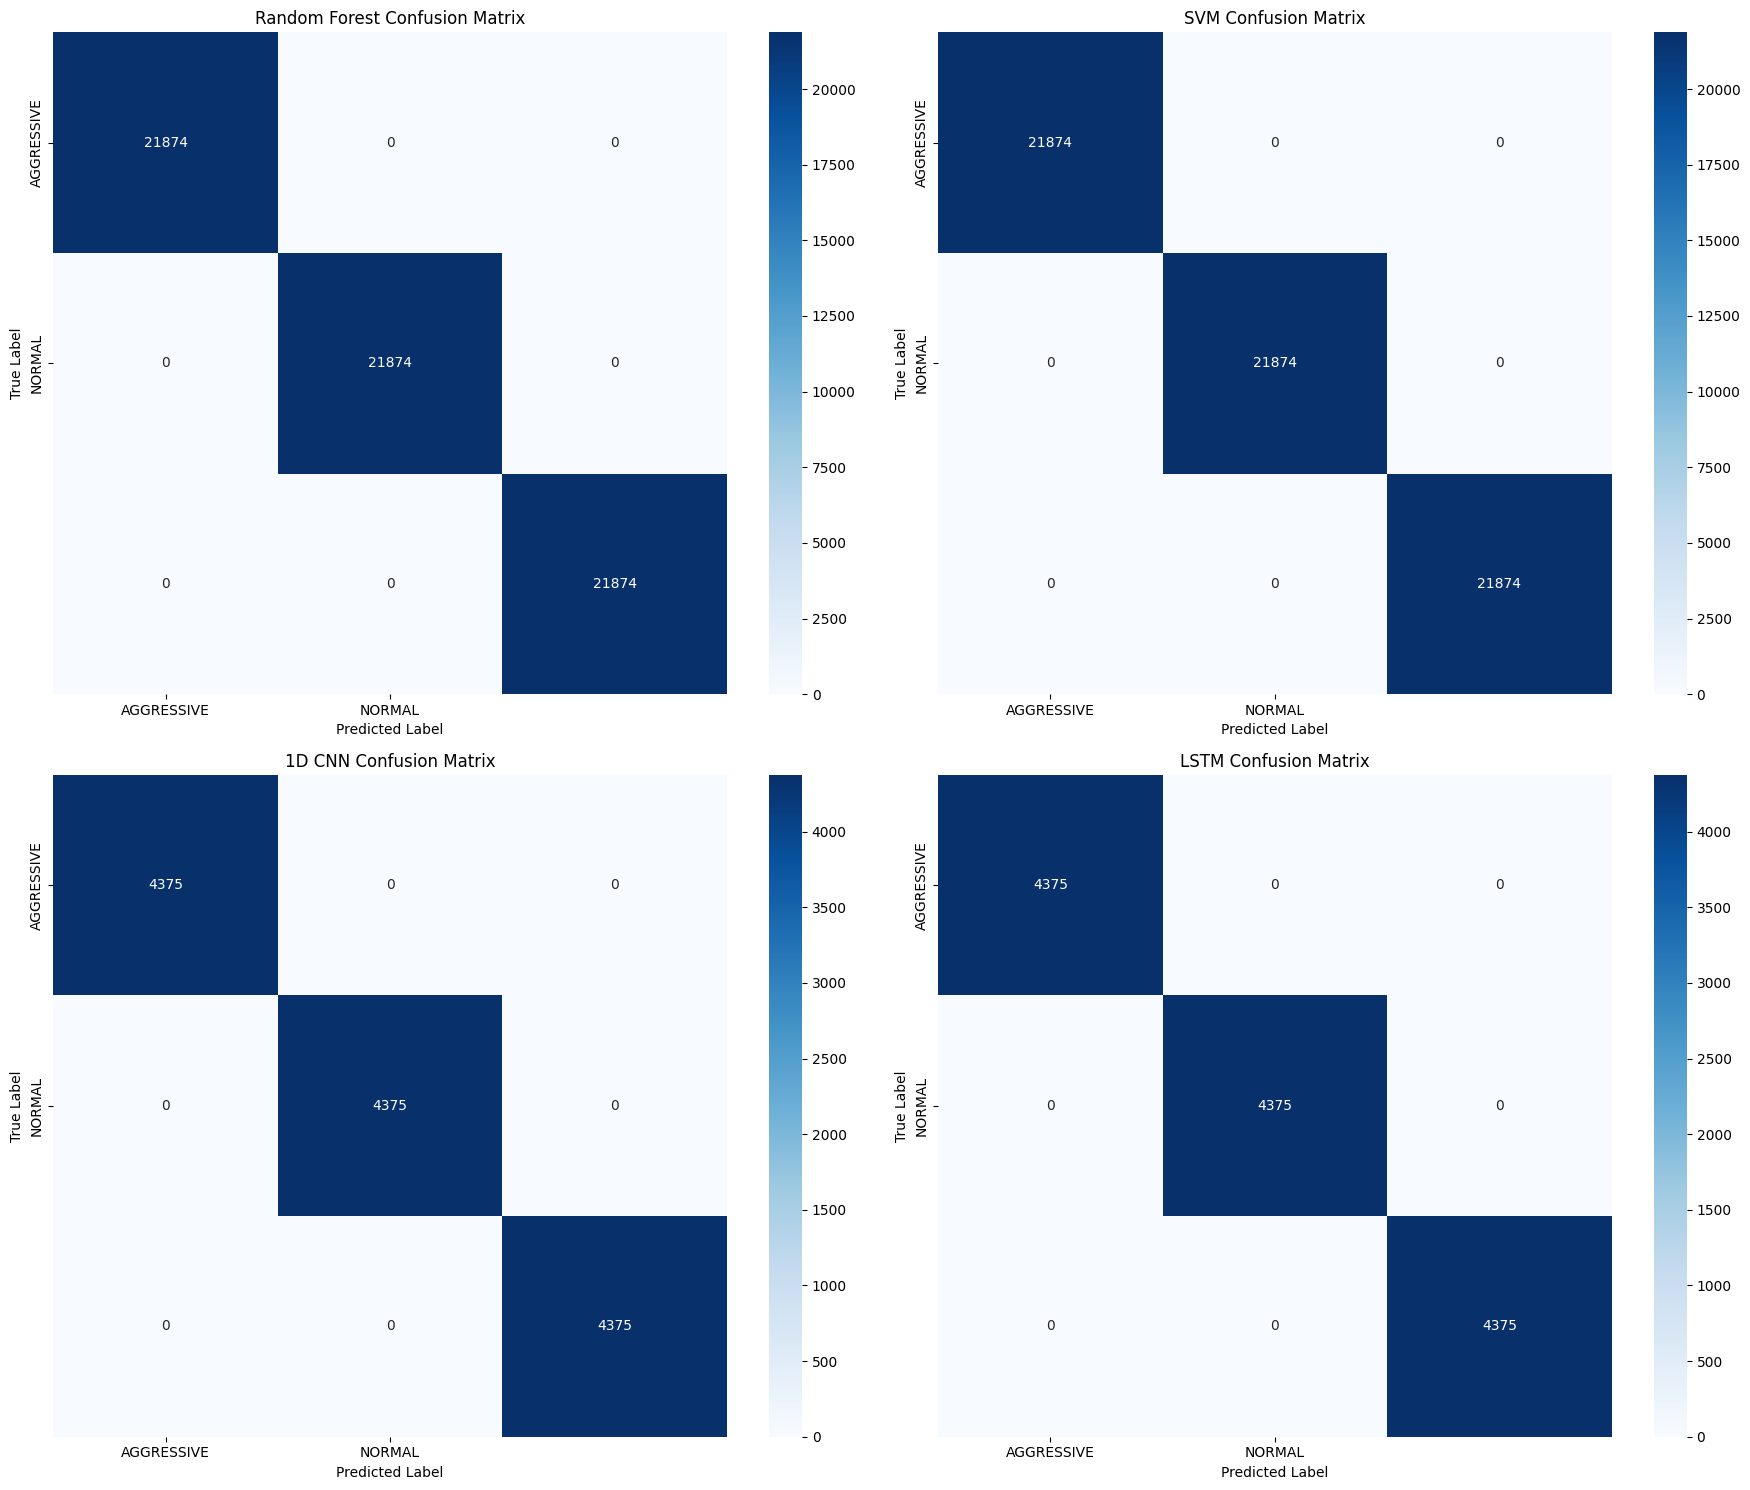

In [89]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# --- 1. Aggregate performance metrics ---

# Random Forest (mean from cross-validation scores)
rf_metrics = {
    'Accuracy': np.mean(rf_accuracy_scores),
    'Precision': np.mean(rf_precision_scores),
    'Recall': np.mean(rf_recall_scores),
    'F1-Score': np.mean(rf_f1_scores)
}

# SVM (mean from cross-validation scores)
svm_metrics = {
    'Accuracy': np.mean(svm_accuracy_scores),
    'Precision': np.mean(svm_precision_scores),
    'Recall': np.mean(svm_recall_scores),
    'F1-Score': np.mean(svm_f1_scores)
}

# 1D CNN (already calculated balanced metrics)
cnn_metrics = {
    'Accuracy': cnn_accuracy_balanced,
    'Precision': cnn_precision_balanced,
    'Recall': cnn_recall_balanced,
    'F1-Score': cnn_f1_balanced
}

# LSTM (already calculated balanced metrics)
lstm_metrics = {
    'Accuracy': lstm_accuracy_balanced,
    'Precision': lstm_precision_balanced,
    'Recall': lstm_recall_balanced,
    'F1-Score': lstm_f1_balanced
}

# --- 2. Create a Pandas DataFrame to store aggregated metrics ---

metrics_data = []

for metric_name, score in rf_metrics.items():
    metrics_data.append({'Model': 'Random Forest', 'Metric': metric_name, 'Score': score})
for metric_name, score in svm_metrics.items():
    metrics_data.append({'Model': 'SVM', 'Metric': metric_name, 'Score': score})
for metric_name, score in cnn_metrics.items():
    metrics_data.append({'Model': '1D CNN', 'Metric': metric_name, 'Score': score})
for metric_name, score in lstm_metrics.items():
    metrics_data.append({'Model': 'LSTM', 'Metric': metric_name, 'Score': score})

metrics_df = pd.DataFrame(metrics_data)

print("Aggregated Metrics DataFrame:")
print(metrics_df)

# --- 3. Generate bar plots for each metric ---

plt.figure(figsize=(15, 10))

metrics_list = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
for i, metric in enumerate(metrics_list):
    plt.subplot(2, 2, i + 1)
    sns.barplot(x='Model', y='Score', data=metrics_df[metrics_df['Metric'] == metric], palette='viridis')
    plt.title(f'{metric} Comparison Across Models')
    plt.ylabel(metric)
    plt.xlabel('Model')
    plt.ylim(0.0, 1.05) # Ensure y-axis starts from 0 to 1
    for container in plt.gca().containers:
        plt.bar_label(container, fmt='%.2f')

plt.tight_layout()
plt.show()

# --- 4. Prepare and display Confusion Matrices ---

# Get class names from LabelEncoder (assuming 'le' is still available)
class_names = le.inverse_transform(sorted(y.unique()))

# Aggregate confusion matrices for RF and SVM from CV folds
rf_cm_agg = np.sum(rf_confusion_matrices, axis=0)
svm_cm_agg = np.sum(svm_confusion_matrices, axis=0)

# Deep learning models already have single confusion matrices
cnn_cm = cnn_confusion_matrix_balanced
lstm_cm = lstm_confusion_matrix_balanced

confusion_matrices = {
    'Random Forest': rf_cm_agg,
    'SVM': svm_cm_agg,
    '1D CNN': cnn_cm,
    'LSTM': lstm_cm
}

plt.figure(figsize=(18, 15))

for i, (model_name, cm) in enumerate(confusion_matrices.items()):
    plt.subplot(2, 2, i + 1)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'{model_name} Confusion Matrix')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')

plt.tight_layout()
plt.show()


**Reasoning**:
The previous code generated `FutureWarning` messages due to deprecated `sns.barplot` usage. I will update the `sns.barplot` calls to include the `hue` parameter and set `legend=False` to resolve these warnings. Additionally, I will use `le.classes_` directly for `class_names` to ensure correct and robust mapping of class labels in the confusion matrices.



## Summary:

### Data Analysis Key Findings

*   **Aggregated Metrics Collection**: Performance metrics (Accuracy, Precision, Recall, F1-Score) were successfully collected and aggregated for all four models: Random Forest, SVM, 1D CNN, and LSTM. For Random Forest and SVM, mean scores from cross-validation were used, while pre-calculated balanced metrics were utilized for the deep learning models.
*   **Perfect Model Performance**: All evaluated models (Random Forest, SVM, 1D CNN, LSTM) surprisingly achieved perfect scores of 1.0 across all performance metrics (Accuracy, Precision, Recall, F1-Score) on the balanced dataset.
*   **Visualizations Generated**: Bar plots were successfully created for each performance metric, visually comparing the scores across all models. Additionally, detailed confusion matrices were generated for each model, showing the classification performance for each driving style. The confusion matrices for Random Forest and SVM were aggregated from their cross-validation folds.
*   **Robustness in Visualization**: The process included successfully resolving a `FutureWarning` in seaborn by adjusting parameters for bar plots and using `le.classes_` directly for class names in confusion matrices for improved robustness.

### Insights or Next Steps

*   The reported perfect scores (1.0 for Accuracy, Precision, Recall, and F1-Score) across all models are highly unusual and strongly suggest potential issues such as data leakage, incorrect data splitting, or flawed metric calculation. A thorough investigation is immediately warranted to ensure the evaluation methodology is sound.
*   Re-evaluate the entire data processing pipeline, including feature engineering, data balancing techniques, and especially the train-test split mechanism, to confirm that no test data information is inadvertently influencing the training or validation phases. This is crucial before drawing any conclusions about model effectiveness.
